# **Random Forest + XGBoost**

**Setup and imports**

In [1]:
# Install dependencies first: pip install -r requirements.txt
# --- NOTEBOOK 2: Random Forest + XGBoost with SHAP ---
# Using Config 4 setup: Class weights + no total_exp


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score, accuracy_score, roc_auc_score
)
import warnings
warnings.filterwarnings('ignore')

**Load data and prepare features (without total_exp)**

In [2]:
# --- Load and prepare data ---
df = pd.read_csv('data/processed/final_for_modeling.csv')
df['hosp_class_label'] = df['hosp_class'].map({0: 'None', 1: 'Single', 2: 'Multiple'})

# Feature definitions
drop_cols = ['DUPERSID', 'panel', 'hospitalized', 'hosp_class', 'hosp_class_label']
nominal_cols = ['race', 'region', 'insurance']
ordinal_cols = ['health_status', 'mental_health', 'poverty_cat']
binary_cols = ['female', 'married', 'employed', 'has_limitation',
               'has_diabetes', 'has_hypertension', 'has_heart_disease',
               'has_copd', 'has_depression', 'has_arthritis', 'has_stroke',
               'polypharmacy']
numerical_cols = ['age', 'er_visits', 'num_conditions', 'num_unique_meds']

# Encode ordinals
df['health_status_num'] = df['health_status'].map({
    'Excellent': 1, 'Very Good': 2, 'Good': 3, 'Fair': 4, 'Poor': 5})
df['mental_health_num'] = df['mental_health'].map({
    'Excellent': 1, 'Very Good': 2, 'Good': 3, 'Fair': 4, 'Poor': 5})
df['poverty_cat_num'] = df['poverty_cat'].map({
    'High Income': 1, 'Middle Income': 2, 'Low Income': 3, 'Near Poor': 4, 'Poor': 5})

# One-hot encode nominals
df_encoded = pd.get_dummies(df, columns=nominal_cols, drop_first=True, dtype=int)

# Drop missing values
all_features = binary_cols + numerical_cols + ['health_status_num', 'mental_health_num', 'poverty_cat_num']
dummy_cols = [c for c in df_encoded.columns if any(c.startswith(n + '_') for n in nominal_cols)]
all_features += dummy_cols
df_clean = df_encoded.dropna(subset=all_features).copy()

# Build feature matrix (NO total_exp)
to_drop = drop_cols + ordinal_cols + ['total_exp']
to_drop = [c for c in to_drop if c in df_clean.columns]
X = df_clean.drop(columns=to_drop)
y = df_clean['hosp_class_label']

# Train-test split (same random state as Notebook 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Features: {X.shape[1]} (total_exp excluded)")
print(f"Train: {X_train.shape[0]:,}  |  Test: {X_test.shape[0]:,}")
print(f"\nClass distribution (train):")
print(y_train.value_counts())

Features: 26 (total_exp excluded)
Train: 40,586  |  Test: 10,147

Class distribution (train):
hosp_class_label
None        37274
Single       2645
Multiple      667
Name: count, dtype: int64


**Random Forest model**

In [3]:
# --- Random Forest with class weights ---

# Calculate class weights manually for reference
from sklearn.utils.class_weight import compute_class_weight

classes_arr = np.array(['None', 'Single', 'Multiple'])
weights = compute_class_weight('balanced', classes=classes_arr, y=y_train)
print("Class weights:")
for c, w in zip(classes_arr, weights):
    print(f"  {c}: {w:.2f}")

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,        # 300 trees
    max_depth=15,            # limiting depth to prevent overfitting
    min_samples_leaf=20,     # each leaf needs at least 20 samples
    class_weight='balanced', # handling imbalance
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
print("\nRandom Forest trained")
print(f"Number of features: {rf_model.n_features_in_}")

Class weights:
  None: 0.36
  Single: 5.11
  Multiple: 20.28

Random Forest trained
Number of features: 26


**Evaluate Random Forest**

RANDOM FOREST RESULTS
  Accuracy:    0.7731
  Macro F1:    0.4596
  Weighted F1: 0.8246
  Macro AUC:   0.8441

Per-Class:
  Multiple    P=0.1617  R=0.5210  F1=0.2468
  None        P=0.9717  R=0.7962  F1=0.8753
  Single      P=0.1713  R=0.5113  F1=0.2566


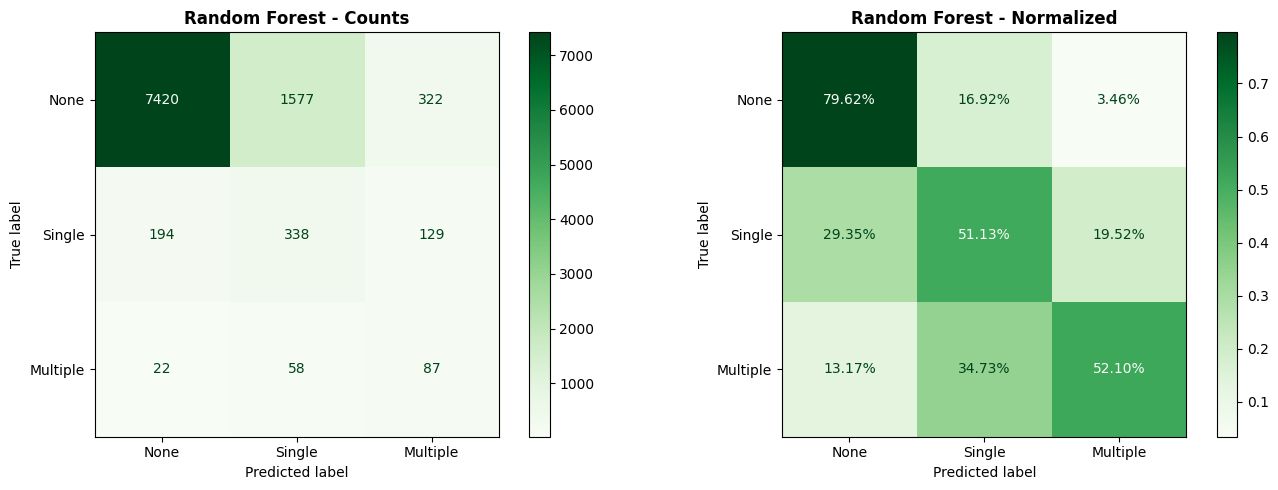

In [4]:
y_pred_rf = rf_model.predict(X_test)
y_pred_proba_rf = rf_model.predict_proba(X_test)

# Overall metrics
acc_rf = accuracy_score(y_test, y_pred_rf)
macro_f1_rf = f1_score(y_test, y_pred_rf, average='macro')
weighted_f1_rf = f1_score(y_test, y_pred_rf, average='weighted')

model_classes = list(rf_model.classes_)
y_test_bin = label_binarize(y_test, classes=model_classes)
macro_auc_rf = roc_auc_score(y_test_bin, y_pred_proba_rf, multi_class='ovr', average='macro')

# Per-class metrics
f1_each = f1_score(y_test, y_pred_rf, average=None, labels=model_classes)
prec_each = precision_score(y_test, y_pred_rf, average=None, labels=model_classes)
rec_each = recall_score(y_test, y_pred_rf, average=None, labels=model_classes)

print("=" * 55)
print("RANDOM FOREST RESULTS")
print("=" * 55)
print(f"  Accuracy:    {acc_rf:.4f}")
print(f"  Macro F1:    {macro_f1_rf:.4f}")
print(f"  Weighted F1: {weighted_f1_rf:.4f}")
print(f"  Macro AUC:   {macro_auc_rf:.4f}")
print(f"\nPer-Class:")
for i, cls in enumerate(model_classes):
    print(f"  {cls:10s}  P={prec_each[i]:.4f}  R={rec_each[i]:.4f}  F1={f1_each[i]:.4f}")

# Confusion matrix
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
class_order = ['None', 'Single', 'Multiple']

cm = confusion_matrix(y_test, y_pred_rf, labels=class_order)
ConfusionMatrixDisplay(cm, display_labels=class_order).plot(ax=ax1, cmap='Greens', values_format='d')
ax1.set_title('Random Forest - Counts', fontweight='bold')

cm_norm = confusion_matrix(y_test, y_pred_rf, labels=class_order, normalize='true')
ConfusionMatrixDisplay(cm_norm, display_labels=class_order).plot(ax=ax2, cmap='Greens', values_format='.2%')
ax2.set_title('Random Forest - Normalized', fontweight='bold')

plt.tight_layout()
plt.show()

**XGBoost model**

In [5]:
# --- XGBoost with class weights ---

# XGBoost needs numeric labels, not strings
label_map = {'None': 0, 'Single': 1, 'Multiple': 2}
reverse_map = {0: 'None', 1: 'Single', 2: 'Multiple'}

y_train_xgb = y_train.map(label_map)
y_test_xgb = y_test.map(label_map)

# Calculate sample weights (XGBoost uses sample_weight instead of class_weight)
sample_weights = y_train.map({
    'None': 0.36,
    'Single': 5.11,
    'Multiple': 20.28
})

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric='mlogloss'
)

xgb_model.fit(X_train, y_train_xgb, sample_weight=sample_weights)
print("XGBoost trained")

XGBoost trained


**Evaluate XGBoost**

XGBOOST RESULTS
  Accuracy:    0.7716
  Macro F1:    0.4501
  Weighted F1: 0.8226
  Macro AUC:   0.8275

Per-Class:
  Multiple    P=0.1540  R=0.3653  F1=0.2167
  None        P=0.9690  R=0.7949  F1=0.8734
  Single      P=0.1709  R=0.5446  F1=0.2602


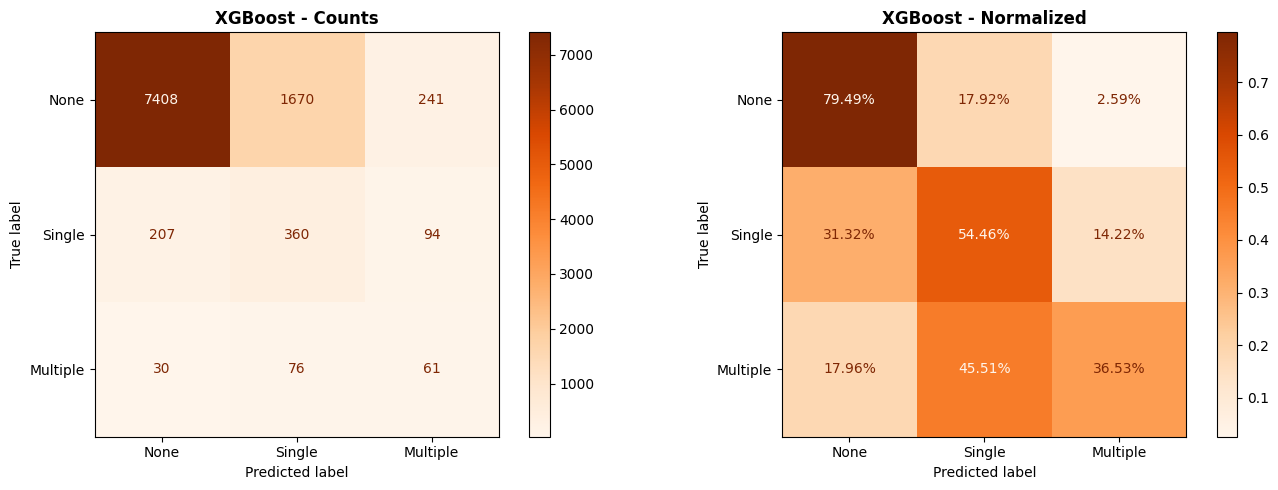

In [6]:
# --- Evaluate XGBoost ---

y_pred_xgb_num = xgb_model.predict(X_test)
y_pred_proba_xgb = xgb_model.predict_proba(X_test)

# Convert numeric predictions back to labels
y_pred_xgb = pd.Series(y_pred_xgb_num).map(reverse_map).values

# Overall metrics
acc_xgb = accuracy_score(y_test, y_pred_xgb)
macro_f1_xgb = f1_score(y_test, y_pred_xgb, average='macro')
weighted_f1_xgb = f1_score(y_test, y_pred_xgb, average='weighted')

xgb_classes = ['Multiple', 'None', 'Single']  # matching label order
y_test_bin_xgb = label_binarize(y_test, classes=xgb_classes)
y_pred_proba_xgb_reordered = y_pred_proba_xgb[:, [2, 0, 1]]
macro_auc_xgb = roc_auc_score(y_test_bin_xgb, y_pred_proba_xgb_reordered,
                               multi_class='ovr', average='macro')

# Per-class metrics
model_classes = ['Multiple', 'None', 'Single']
f1_each = f1_score(y_test, y_pred_xgb, average=None, labels=model_classes)
prec_each = precision_score(y_test, y_pred_xgb, average=None, labels=model_classes)
rec_each = recall_score(y_test, y_pred_xgb, average=None, labels=model_classes)

print("=" * 55)
print("XGBOOST RESULTS")
print("=" * 55)
print(f"  Accuracy:    {acc_xgb:.4f}")
print(f"  Macro F1:    {macro_f1_xgb:.4f}")
print(f"  Weighted F1: {weighted_f1_xgb:.4f}")
print(f"  Macro AUC:   {macro_auc_xgb:.4f}")
print(f"\nPer-Class:")
for i, cls in enumerate(model_classes):
    print(f"  {cls:10s}  P={prec_each[i]:.4f}  R={rec_each[i]:.4f}  F1={f1_each[i]:.4f}")

# Confusion matrix
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
class_order = ['None', 'Single', 'Multiple']

cm = confusion_matrix(y_test, y_pred_xgb, labels=class_order)
ConfusionMatrixDisplay(cm, display_labels=class_order).plot(ax=ax1, cmap='Oranges', values_format='d')
ax1.set_title('XGBoost - Counts', fontweight='bold')

cm_norm = confusion_matrix(y_test, y_pred_xgb, labels=class_order, normalize='true')
ConfusionMatrixDisplay(cm_norm, display_labels=class_order).plot(ax=ax2, cmap='Oranges', values_format='.2%')
ax2.set_title('XGBoost - Normalized', fontweight='bold')

plt.tight_layout()
plt.show()

**SHAP values for Random Forest**

In [8]:
# Using a sample of test data to speed up SHAP (full test set takes too long)
np.random.seed(42)
sample_idx = np.random.choice(X_test.index, size=1000, replace=False)
X_test_sample = X_test.loc[sample_idx]

print("Calculating SHAP values for Random Forest")

# TreeExplainer is fast for tree-based models
rf_explainer = shap.TreeExplainer(rf_model)
rf_shap_values = rf_explainer.shap_values(X_test_sample)

# rf_shap_values is a list of 3 arrays (one per class)
# Index: 0=Multiple, 1=None, 2=Single (alphabetical order matching rf_model.classes_)
print(f"\nSHAP values calculated")
print(f"Classes: {list(rf_model.classes_)}")
print(f"Shape per class: {rf_shap_values[0].shape}")

Calculating SHAP values for Random Forest

SHAP values calculated
Classes: ['Multiple', 'None', 'Single']
Shape per class: (26, 3)


**Check SHAP format and plot for Random Forest**

In [9]:
# --- Check SHAP output format ---
print(f"Type: {type(rf_shap_values)}")

if isinstance(rf_shap_values, np.ndarray):
    print(f"Array shape: {rf_shap_values.shape}")
elif isinstance(rf_shap_values, list):
    print(f"List of {len(rf_shap_values)} arrays")
    for i, sv in enumerate(rf_shap_values):
        print(f"  Class {rf_model.classes_[i]}: shape {sv.shape}")

# Handle different SHAP output formats
if isinstance(rf_shap_values, np.ndarray) and rf_shap_values.ndim == 3:
    # Shape is (samples, features, classes)
    rf_shap_multiple = rf_shap_values[:, :, list(rf_model.classes_).index('Multiple')]
    rf_shap_single = rf_shap_values[:, :, list(rf_model.classes_).index('Single')]
    rf_shap_none = rf_shap_values[:, :, list(rf_model.classes_).index('None')]
elif isinstance(rf_shap_values, list):
    # List of arrays, one per class
    mult_idx = list(rf_model.classes_).index('Multiple')
    single_idx = list(rf_model.classes_).index('Single')
    none_idx = list(rf_model.classes_).index('None')
    rf_shap_multiple = rf_shap_values[mult_idx]
    rf_shap_single = rf_shap_values[single_idx]
    rf_shap_none = rf_shap_values[none_idx]

print(f"\nMultiple SHAP shape: {rf_shap_multiple.shape}")
print(f"Single SHAP shape: {rf_shap_single.shape}")
print(f"None SHAP shape: {rf_shap_none.shape}")

Type: <class 'numpy.ndarray'>
Array shape: (1000, 26, 3)

Multiple SHAP shape: (1000, 26)
Single SHAP shape: (1000, 26)
None SHAP shape: (1000, 26)


**SHAP plots for Random Forest**

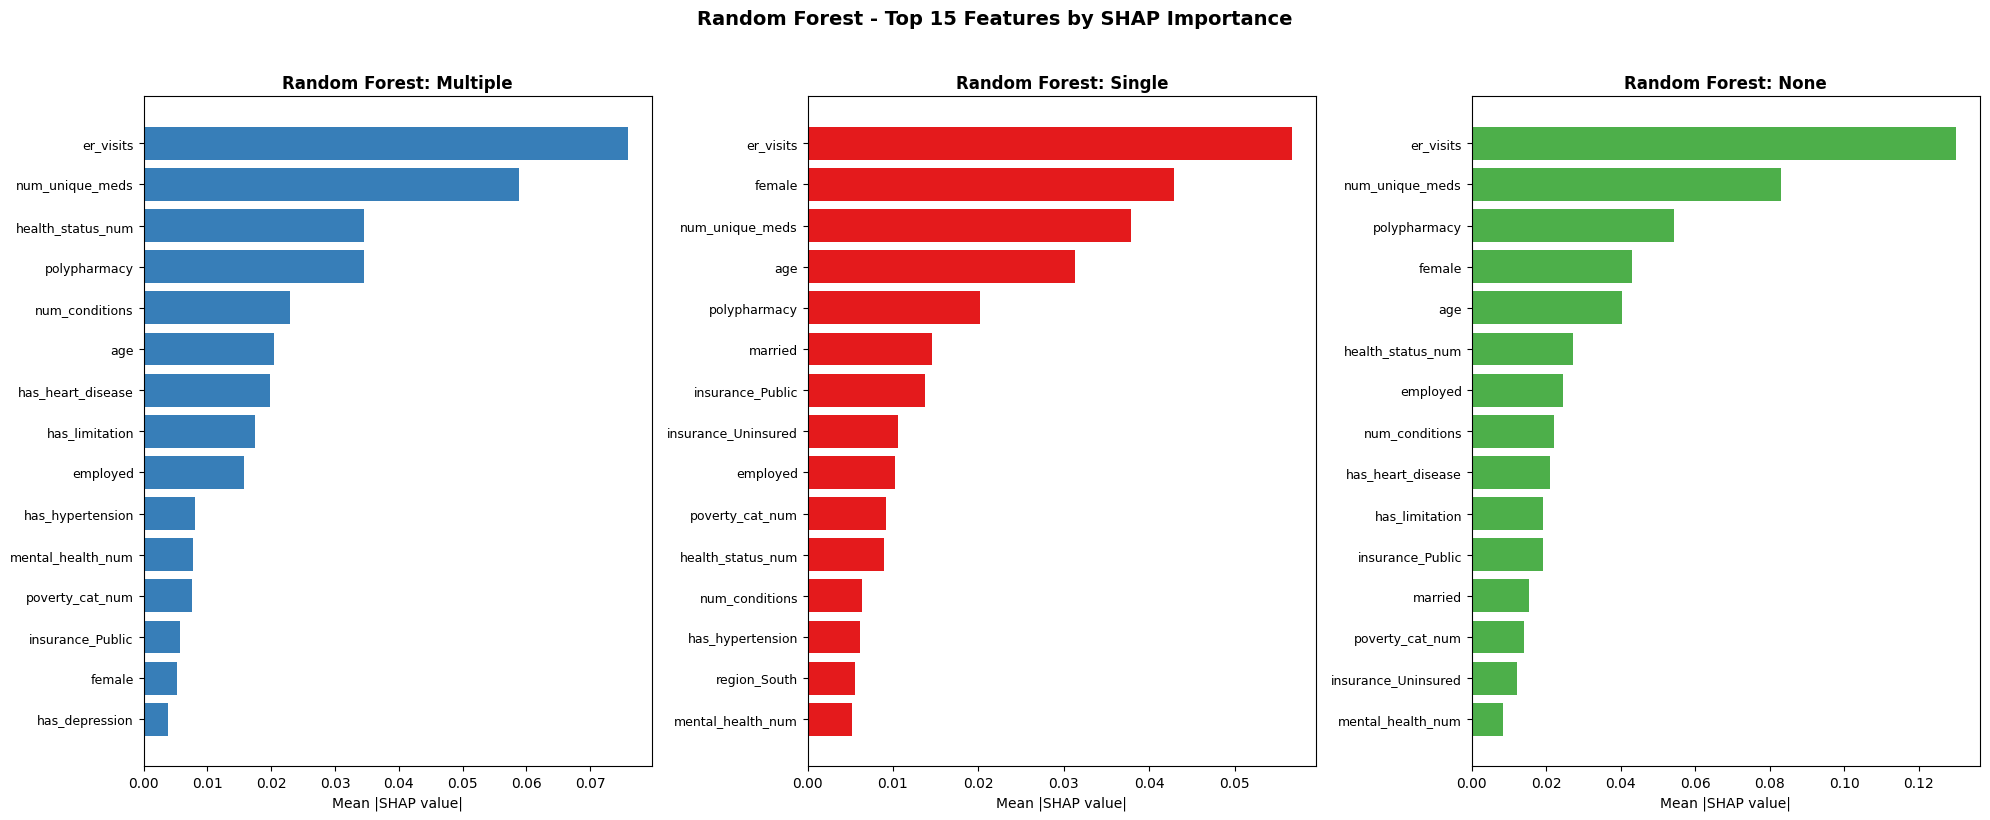

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 8))

class_names = ['Multiple', 'Single', 'None']
shap_arrays = [rf_shap_multiple, rf_shap_single, rf_shap_none]

for idx, (cls_name, shap_vals) in enumerate(zip(class_names, shap_arrays)):
    # Getting mean absolute SHAP value per feature (overall importance)
    mean_shap = np.abs(shap_vals).mean(axis=0)
    feature_importance = pd.Series(mean_shap, index=X_test_sample.columns)
    top15 = feature_importance.sort_values(ascending=True).tail(15)

    axes[idx].barh(range(len(top15)), top15.values, color='#377EB8' if cls_name == 'Multiple'
                   else '#E41A1C' if cls_name == 'Single' else '#4DAF4A')
    axes[idx].set_yticks(range(len(top15)))
    axes[idx].set_yticklabels(top15.index, fontsize=9)
    axes[idx].set_xlabel('Mean |SHAP value|')
    axes[idx].set_title(f'Random Forest: {cls_name}', fontweight='bold')

plt.suptitle('Random Forest - Top 15 Features by SHAP Importance',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**SHAP values for XGBoost**

In [12]:
print("Calculating SHAP values for XGBoost...")

xgb_explainer = shap.TreeExplainer(xgb_model)
xgb_shap_values = xgb_explainer.shap_values(X_test_sample)

print(f"Type: {type(xgb_shap_values)}")

if isinstance(xgb_shap_values, np.ndarray):
    print(f"Array shape: {xgb_shap_values.shape}")
elif isinstance(xgb_shap_values, list):
    print(f"List of {len(xgb_shap_values)} arrays")
    for i, sv in enumerate(xgb_shap_values):
        print(f"  Class {i} ({reverse_map[i]}): shape {sv.shape}")

Calculating SHAP values for XGBoost...
Type: <class 'numpy.ndarray'>
Array shape: (1000, 26, 3)


**SHAP plots for XGBoost**

Multiple SHAP shape: (1000, 26)
Single SHAP shape: (1000, 26)
None SHAP shape: (1000, 26)


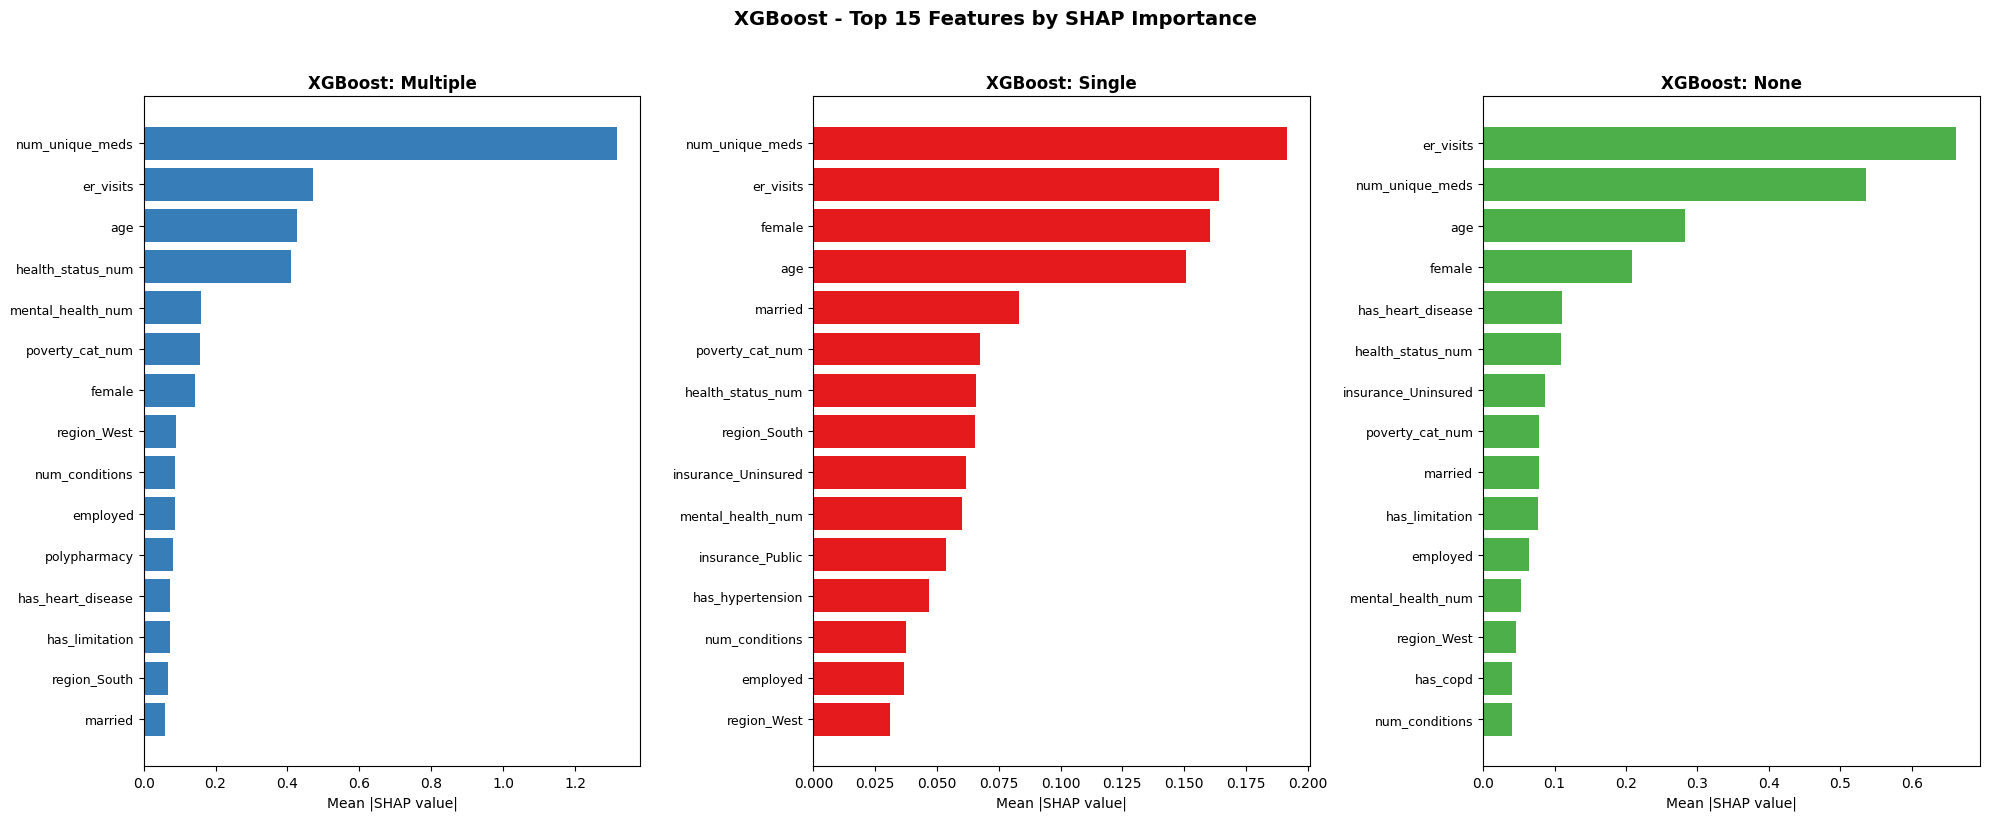

In [13]:
# Handle SHAP format for XGBoost
# XGBoost label_map: None=0, Single=1, Multiple=2
if isinstance(xgb_shap_values, np.ndarray) and xgb_shap_values.ndim == 3:
    xgb_shap_multiple = xgb_shap_values[:, :, 2]  # Multiple = 2
    xgb_shap_single = xgb_shap_values[:, :, 1]    # Single = 1
    xgb_shap_none = xgb_shap_values[:, :, 0]      # None = 0
elif isinstance(xgb_shap_values, list):
    xgb_shap_multiple = xgb_shap_values[2]  # Multiple = 2
    xgb_shap_single = xgb_shap_values[1]    # Single = 1
    xgb_shap_none = xgb_shap_values[0]      # None = 0

print(f"Multiple SHAP shape: {xgb_shap_multiple.shape}")
print(f"Single SHAP shape: {xgb_shap_single.shape}")
print(f"None SHAP shape: {xgb_shap_none.shape}")

# Plot
fig, axes = plt.subplots(1, 3, figsize=(20, 8))

class_names = ['Multiple', 'Single', 'None']
shap_arrays = [xgb_shap_multiple, xgb_shap_single, xgb_shap_none]

for idx, (cls_name, shap_vals) in enumerate(zip(class_names, shap_arrays)):
    mean_shap = np.abs(shap_vals).mean(axis=0)
    feature_importance = pd.Series(mean_shap, index=X_test_sample.columns)
    top15 = feature_importance.sort_values(ascending=True).tail(15)

    axes[idx].barh(range(len(top15)), top15.values, color='#377EB8' if cls_name == 'Multiple'
                   else '#E41A1C' if cls_name == 'Single' else '#4DAF4A')
    axes[idx].set_yticks(range(len(top15)))
    axes[idx].set_yticklabels(top15.index, fontsize=9)
    axes[idx].set_xlabel('Mean |SHAP value|')
    axes[idx].set_title(f'XGBoost: {cls_name}', fontweight='bold')

plt.suptitle('XGBoost - Top 15 Features by SHAP Importance',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [14]:
import os
os.makedirs("outputs", exist_ok=True)
# --- Final 3-Model Comparison Table ---

# Load logistic regression results from Notebook 1
logreg_comparison = pd.read_csv('outputs/logreg_comparison.csv')

# Get Config 4 (Weighted + no total_exp) row
logreg_row = logreg_comparison[logreg_comparison['Configuration'] == 'Weighted + no total_exp'].iloc[0]

# Build comparison
final_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [logreg_row['Accuracy'], acc_rf, acc_xgb],
    'Macro F1': [logreg_row['Macro F1'], macro_f1_rf, macro_f1_xgb],
    'Weighted F1': [logreg_row['Weighted F1'], weighted_f1_rf, weighted_f1_xgb],
    'Macro AUC': [logreg_row['Macro AUC'], macro_auc_rf, macro_auc_xgb],
    'Multiple F1': [logreg_row['Multiple F1'],
                    f1_score(y_test, y_pred_rf, average=None, labels=['Multiple'])[0],
                    f1_score(y_test, y_pred_xgb, average=None, labels=['Multiple'])[0]],
    'Single F1': [logreg_row['Single F1'],
                  f1_score(y_test, y_pred_rf, average=None, labels=['Single'])[0],
                  f1_score(y_test, y_pred_xgb, average=None, labels=['Single'])[0]],
    'None F1': [logreg_row['None F1'],
                f1_score(y_test, y_pred_rf, average=None, labels=['None'])[0],
                f1_score(y_test, y_pred_xgb, average=None, labels=['None'])[0]],
    'Multiple Recall': [logreg_row['Multiple Recall'],
                        recall_score(y_test, y_pred_rf, average=None, labels=['Multiple'])[0],
                        recall_score(y_test, y_pred_xgb, average=None, labels=['Multiple'])[0]],
    'Single Recall': [logreg_row['Single Recall'],
                      recall_score(y_test, y_pred_rf, average=None, labels=['Single'])[0],
                      recall_score(y_test, y_pred_xgb, average=None, labels=['Single'])[0]]
}).round(4)

print("=" * 80)
print("FINAL MODEL COMPARISON (All using Class Weights + No total_exp)")
print("=" * 80)
print(final_comparison.to_string(index=False))

# Save to outputs/
final_comparison.to_csv('outputs/final_model_comparison.csv', index=False)
print("\nSaved to outputs/")

FINAL MODEL COMPARISON (All using Class Weights + No total_exp)
              Model  Accuracy  Macro F1  Weighted F1  Macro AUC  Multiple F1  Single F1  None F1  Multiple Recall  Single Recall
Logistic Regression    0.7299    0.4096       0.7962     0.8071       0.1868     0.1921   0.8499           0.6287         0.3737
      Random Forest    0.7731    0.4596       0.8246     0.8441       0.2468     0.2566   0.8753           0.5210         0.5113
            XGBoost    0.7716    0.4501       0.8226     0.8275       0.2167     0.2602   0.8734           0.3653         0.5446

Saved to outputs/


**Comparison visualization and save**

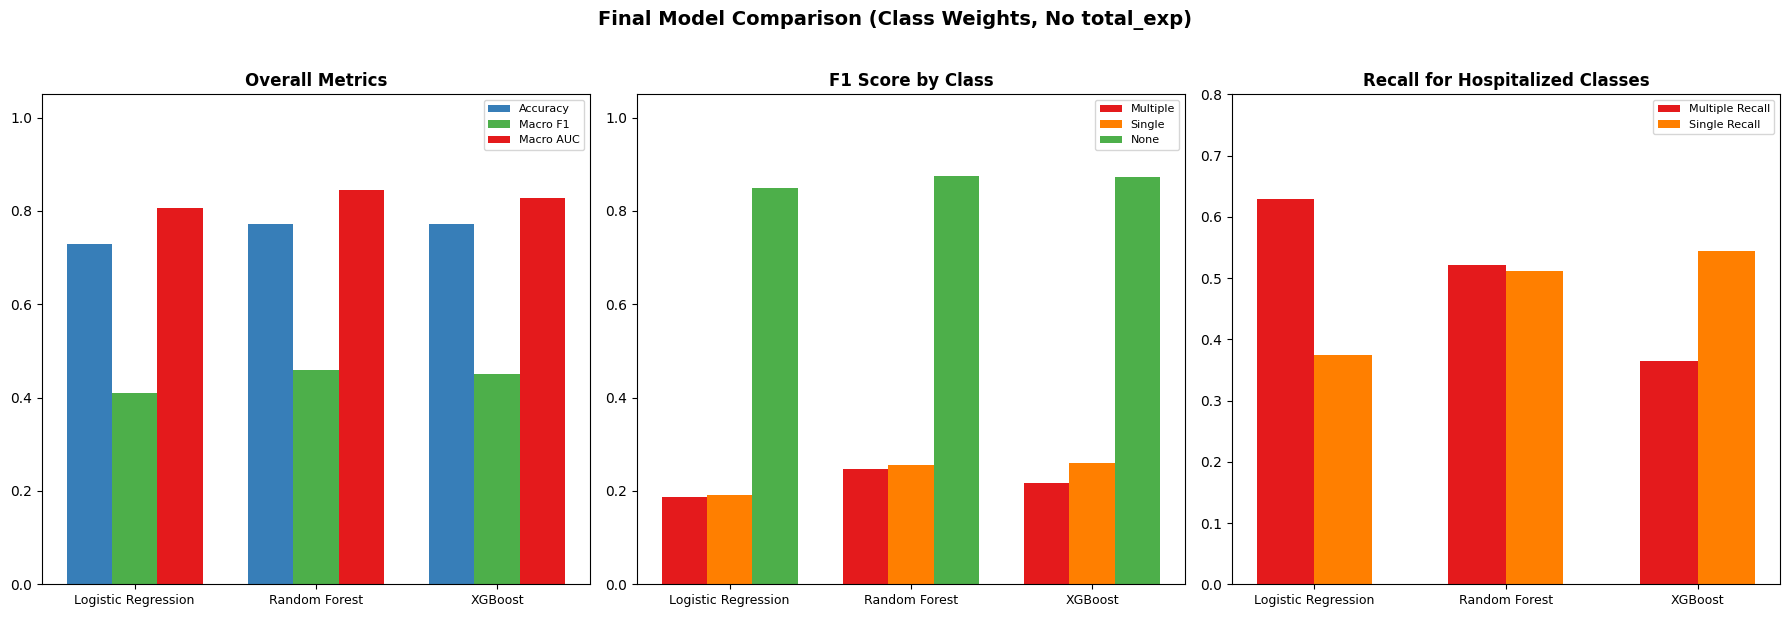

In [16]:
# --- Final comparison visualization ---

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
models = final_comparison['Model'].tolist()
colors = ['#377EB8', '#4DAF4A', '#E41A1C']
x = np.arange(len(models))

# Plot 1: Overall metrics
metrics = ['Accuracy', 'Macro F1', 'Macro AUC']
width = 0.25
for i, metric in enumerate(metrics):
    vals = final_comparison[metric].tolist()
    axes[0].bar(x + i*width, vals, width, label=metric,
                color=['#377EB8', '#4DAF4A', '#E41A1C'][i])
axes[0].set_xticks(x + width)
axes[0].set_xticklabels(models, fontsize=9)
axes[0].set_title('Overall Metrics', fontweight='bold')
axes[0].set_ylim(0, 1.05)
axes[0].legend(fontsize=8)

# Plot 2: Per-class F1
class_f1s = ['Multiple F1', 'Single F1', 'None F1']
for i, metric in enumerate(class_f1s):
    vals = final_comparison[metric].tolist()
    axes[1].bar(x + i*width, vals, width, label=metric.replace(' F1', ''),
                color=['#E41A1C', '#FF7F00', '#4DAF4A'][i])
axes[1].set_xticks(x + width)
axes[1].set_xticklabels(models, fontsize=9)
axes[1].set_title('F1 Score by Class', fontweight='bold')
axes[1].set_ylim(0, 1.05)
axes[1].legend(fontsize=8)

# Plot 3: Multiple and Single Recall
recall_metrics = ['Multiple Recall', 'Single Recall']
for i, metric in enumerate(recall_metrics):
    vals = final_comparison[metric].tolist()
    axes[2].bar(x + i*0.3, vals, 0.3, label=metric,
                color=['#E41A1C', '#FF7F00'][i])
axes[2].set_xticks(x + 0.15)
axes[2].set_xticklabels(models, fontsize=9)
axes[2].set_title('Recall for Hospitalized Classes', fontweight='bold')
axes[2].set_ylim(0, 0.8)
axes[2].legend(fontsize=8)

plt.suptitle('Final Model Comparison (Class Weights, No total_exp)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
